# Weekend 1 — one chart and one number

**This is the whole goal for today:**

1. Get the data and look at it.
2. Draw the picture of US flu hospital admissions over the last 4.5 years.
3. Make the dumbest possible forecast — *"same week last year"* — and measure how wrong it is.

That last number is your **yardstick**. Every model you build after today has exactly one job:
beat it. If nothing beats it, that is a real finding and you say so out loud.

You are not doing SARIMA, Docker, or anything with the word *deploy* in it today.

---

### How to work through this

Cells marked **SETUP** are plumbing — just run them, nothing to learn there.

Cells marked **YOUR TURN** are yours to write. Each has a hint you can uncomment if stuck.
Answers are in `weekend1_solutions.md` — check them *after* you try, same as the drills.

### Where this data comes from

`cdcepi/FluSight-forecast-hub` on GitHub — the repo CDC runs its public flu forecasting
challenge from. `target-data/target-hospital-admissions.csv` is the official series that all 96
competing teams are scored against. That matters later: it means you can compare yourself to
real forecasting teams instead of grading your own homework.

## SETUP — check your tools

If this cell errors, stop and tell Claude. Nothing below will work.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print('pandas', pd.__version__)
print('ready')

pandas 3.0.5
ready


## SETUP — get the data

This downloads straight from GitHub into a DataFrame. No file to save, no folder to manage.

Every row is **one location, one week**: how many people that state admitted to hospital with
confirmed flu that week.

In [2]:
URL = ('https://raw.githubusercontent.com/cdcepi/FluSight-forecast-hub/'
       'main/target-data/target-hospital-admissions.csv')

raw = pd.read_csv(URL, parse_dates=['date'])

print(raw.shape)
raw.head()

(12243, 5)


,date,location,location_name,value,weekly_rate
0,2026-07-04,20,Kansas,3.0,0.100989
1,2026-07-04,55,Wisconsin,3.0,0.050327
2,2026-07-04,50,Vermont,0.0,0.000000
3,2026-07-04,18,Indiana,10.0,0.144419
4,2026-07-04,38,North Dakota,4.0,0.502154


## YOUR TURN 1 — get to the national series

`raw` has all 53 locations stacked on top of each other. You want just the national one.

Build a DataFrame called `us` that:
- keeps only the rows where `location` is `'US'`
- is **sorted by date, oldest first** (this matters more than you'd think — everything below
  assumes the rows are in time order)

Then print how many rows you have, and the first and last date.

*Expect 231 rows, running from Feb 2022 to Jul 2026.*

In [3]:
# your code here

us = raw[raw['location'] == 'US'].sort_values('date').reset_index(drop=True)
print(len(us), us['date'].min(), us['date'].max())

# --- hint: uncomment if stuck ---
# us = raw[raw['location'] == 'US'].sort_values('date').reset_index(drop=True)
# print(len(us), us['date'].min(), us['date'].max())

231 2022-02-05 00:00:00 2026-07-04 00:00:00


## YOUR TURN 2 — draw the picture

Plot `value` (weekly admissions) against `date` as a line.

Give it a title and label the y-axis. Make it wide — `figsize=(14, 5)` — because 231 weeks
squeezed into a small square tells you nothing.

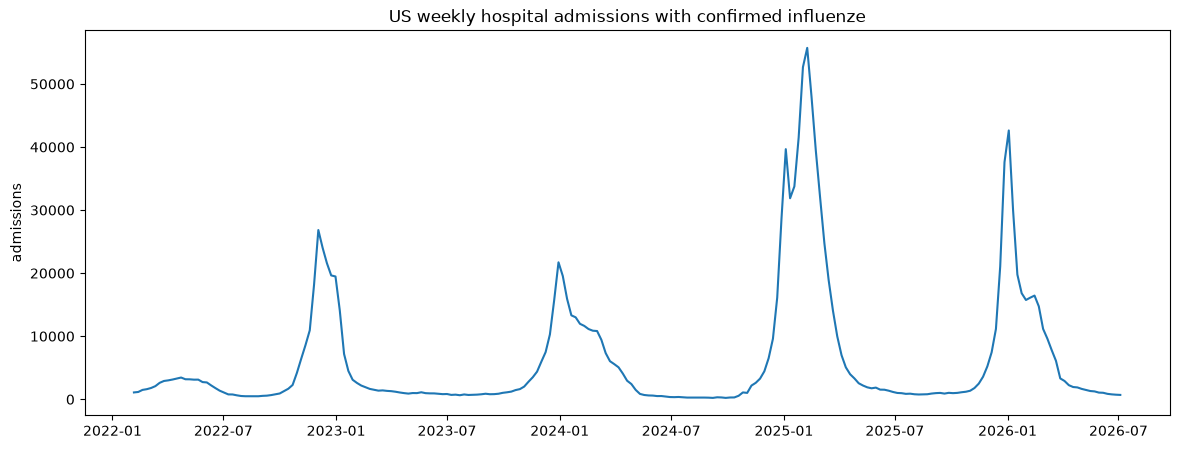

In [5]:
# your code here

fig, ax = plt.subplots(figsize=(14,5))
ax.plot(us['date'], us['value'])
ax.set_title('US weekly hospital admissions with confirmed influenze')
ax.set_ylabel('admissions')
plt.show()

# --- hint: uncomment if stuck ---
# fig, ax = plt.subplots(figsize=(14, 5))
# ax.plot(us['date'], us['value'])
# ax.set_title('US weekly hospital admissions with confirmed influenza')
# ax.set_ylabel('admissions')
# plt.show()

### Stop and actually look at it

Before moving on, answer these for yourself. This is the part people skip, and it is the part
that makes you sound like you know the data in an interview.

1. **How many winter spikes do you count?** That is how many flu seasons you have to learn from.
2. **Are the spikes the same height?** Look at winter 2022-23 against 2024-25.
3. **How low does summer go?** Compare a summer week to a peak week.
4. **Does anything look wrong** — a flat stretch, a sudden step, a gap?

Write your answers in the cell below. You will be asked versions of all four in an interview.

**My answers:**

**1. Four winter spikes** — 2022-23, 2023-24, 2024-25, 2025-26. So four seasons of history to
learn from, which is thin for estimating a yearly pattern and is worth saying out loud before
someone else points it out.

**2. No — they vary by 2.6x.**

| Season | Peak admissions | Peak week |
|---|---|---|
| 2022-23 | 26,835 | 3 Dec |
| 2023-24 | 21,720 | 30 Dec |
| 2024-25 | **55,718** | 8 Feb |
| 2025-26 | 42,626 | 3 Jan |

The two earlier seasons are much smaller than 2024-25.

**3. Summer drops to almost nothing** — the low is **223** admissions (Sep 2024) against a peak of
55,718. A **250x range**. This is why MAPE is useless on this series: a 200-admission miss in July
is a huge percentage and operationally irrelevant. Report MAE.

**4. The 2024-25 season has a double peak.** It rose to 39,662 on 4 Jan, fell back to 31,876 on
11 Jan, then climbed again to its real peak of 55,718 on 8 Feb — a ~20% dip between two peaks.

---

### What these four add up to

Look at the peak-week column: the peak moves from **3 December to 8 February** across four
seasons — a **10-week swing** — while the heights vary **2.6x**.

So seasons differ in two independent ways: **amplitude** (how big) and **phase** (when).
Seasonal naive assumes both are fixed — that this year repeats last year exactly 52 weeks later.
It is wrong on both counts, and a phase error on a curve this steep is brutal: it lines a peak
week up against an off-peak week and misses by tens of thousands.

**That is the explanation for MAE = 4,780**, and it is the reason the rest of this project has a
job to do. Any model worth building has to handle a season that is taller, or later, than the
one before it.

## The dumb forecast — what "seasonal naive" actually means

Here is the entire method:

> **To predict this week, use the same week one year ago.**

That's it. No model, no training, no maths. Flu is seasonal, so last year's January is a
genuinely reasonable guess for this year's January.

It has a fancy name — *seasonal naive* — but do not let the name make it sound clever.
It is a lookup.

**Why bother?** Because it is your yardstick. "My model got an average error of 3,000" means
nothing on its own. "My model got 3,000 where the same-week-last-year lookup got 4,800" is a
result. Most portfolio projects skip this step, which is exactly why theirs don't count.

And fair warning: **seasonal naive is genuinely hard to beat.** If it wins, that is a finding,
not a failure.

### The mechanic

Your rows are weekly and in date order, so "one year ago" is **52 rows up**.
`pandas` does this with `.shift(52)` — it slides the whole column down by 52 positions.
The first 52 rows end up empty, because there is no previous year for them yet.

## YOUR TURN 3 — build the forecast

Add a column to `us` called `pred_naive`: the `value` column shifted down 52 rows.

Then show rows 50 to 56 with just `date`, `value` and `pred_naive`, so you can see with your own
eyes where the predictions start and check the shift lined up the way you expect.

In [6]:
# your code here

us['pred_naive'] = us['value'].shift(52)
us.loc[50:56, ['date', 'value', 'pred_naive']]

# --- hint: uncomment if stuck ---
# us['pred_naive'] = us['value'].shift(52)
# us.loc[50:56, ['date', 'value', 'pred_naive']]

,date,value,pred_naive
50,2023-01-21,4497.0,NaN
51,2023-01-28,3097.0,NaN
52,2023-02-04,2595.0,1089.0
53,2023-02-11,2181.0,1160.0
54,2023-02-18,1906.0,1490.0
55,2023-02-25,1647.0,1604.0
56,2023-03-04,1505.0,1792.0


## YOUR TURN 4 — score it

Now measure how wrong the guess was, using **MAE** — mean absolute error.

Plain English: for every week, how far off were you? Ignore whether you were over or under
(that's the *absolute* part), then average it. **MAE is in admissions**, so an MAE of 4,800
means "on a typical week this guess was off by about 4,800 admissions."

Steps:
1. Drop the rows where `pred_naive` is empty — the first 52 weeks have nothing to compare against.
2. Take `value` minus `pred_naive`, make it absolute, take the mean.
3. Print the MAE **and** how many weeks you scored it on. Always report the second one; an error
   figure without a sample size behind it is not a result.

In [11]:
# your code here

scored = us.dropna(subset=['pred_naive'])
mae = (scored['value'] - scored['pred_naive']).abs().mean()
print(f'seasonal naive MAE: {mae:,.0f} admissions, over {len(scored)} weeks')
print(scored['date'].min(), scored['date'].max())

# --- hint: uncomment if stuck ---
# scored = us.dropna(subset=['pred_naive'])
# mae = (scored['value'] - scored['pred_naive']).abs().mean()
# print(f'seasonal naive MAE: {mae:,.0f} admissions, over {len(scored)} weeks')

seasonal naive MAE: 4,780 admissions, over 179 weeks
2023-02-04 00:00:00 2026-07-04 00:00:00


## Write the number down

This is the deliverable for the whole weekend. Fill it in:

| | |
|---|---|
| **Baseline** | seasonal naive (same week last year) |
| **MAE** | 4780|
| **Weeks scored** | 179|
| **Date range scored** |2023-02-04 - 2026-07-04|
| **Date I ran this** | 2026-09-05|

Everything from here on gets compared against that MAE.

## Stretch — only if you have energy left

MAE averages every week together, which hides something important. Find the **10 worst weeks**:
sort by absolute error, biggest first, and look at *when* they happened.

You will almost certainly find they are all clustered in the same part of the year. Work out why,
and you have the answer to *"when did your model fail worst, and why?"* — an interview question
you will definitely be asked, and one most candidates have no real answer to.

In [ ]:
# your code here



# --- hint: uncomment if stuck ---
# scored = us.dropna(subset=['pred_naive']).copy()
# scored['abs_error'] = (scored['value'] - scored['pred_naive']).abs()
# scored.nlargest(10, 'abs_error')[['date', 'value', 'pred_naive', 'abs_error']]

---

## When you're done

You should have: **one chart**, **one MAE number**, and four written observations about the data.

That's weekend 1 finished. Next time is Holt-Winters and SARIMA — the first real models — and
they only make sense now that there is something to beat.

Plan of record: `../capstone-forecast-project.md`